# 00-MAIN-Pipeline: Building Age Classification (Madrid -> Amsterdam)
**Only Anselmo edits this notebook.** Others work in their own notebooks and send finished code.

Run order: raw data -> Step 1 Clean -> Step 2 Features -> Step 3 Madrid -> Step 4 Amsterdam -> Step 5 Results.
Final test: set both SKIP flags to `False`, then **Kernel > Restart Kernel and Run All Cells** (about 25 min).

In [1]:
# ===== SETTINGS ONLY =====
SEED = 42
SHOTS = [5, 25, 50, 100, 200]
N_TRIALS = 10
METHOD = "blend3"
EVENTS = {"Madrid": 1960, "Amsterdam": 1945}
SKIP_CLEAN = False       # set False for the final full run
SKIP_FEATURES = False    # set False for the final full run
RUN_MADRID_CV = True    # 5-fold cross-validation on Madrid (Step 3)

In [2]:
%load_ext autoreload
%autoreload 2
import os, json, random
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
import data_prep as dp, features_v3 as fv3, transfer_v3 as tv3
assert hasattr(dp, "TEMPORAL_FACTOR"), "old data_prep.py: needs the temporal haze rule"
assert hasattr(tv3, "smooth_proba"), "old transfer_v3.py: upload the latest version"
assert SEED == tv3.SEED, f"SEED {SEED} must equal transfer_v3.SEED {tv3.SEED}"
random.seed(SEED); np.random.seed(SEED)
os.makedirs("clean", exist_ok=True); os.makedirs("models", exist_ok=True)
CITIES = list(EVENTS)
RAW = {"Madrid": "data/madrid_train.parquet", "Amsterdam": "data/amsterdam_data.parquet"}
CLEAN = lambda c: f"clean/clean_{c.lower()}.parquet"
FEATS = lambda c: f"features_{c.lower()}_v3.parquet"
print("scaling mode:", tv3.SCALING)

scaling mode: own


## Step 1 - Clean (owner: Jian)
Raw parquet -> cloud-masked table with one value per pixel-year plus `age_class`. Saved to `clean/`.

In [3]:
for city in CITIES:
    out = CLEAN(city)
    if SKIP_CLEAN and os.path.exists(out):
        print("[skip]", out); continue
    raw = dp.load_city(RAW[city])
    clean = dp.add_age_class(dp.clean_long_table(raw), EVENTS[city])
    clean.to_parquet(out)
    print(city, clean.shape, "->", out)
    del raw, clean

temporal haze filter removed 32,848 photos (0.37% of clean photos)
Madrid (3161994, 17) -> clean/clean_madrid.parquet
temporal haze filter removed 15,513 photos (0.68% of clean photos)
Amsterdam (1053575, 17) -> clean/clean_amsterdam.parquet


## Step 2 - Features (owner: Fenny)
`features_v3.build_features`: one row per pixel, 132 features, label kept separate. Saved to `features_<city>_v3.parquet` and `feature_cols_v3.json`.

In [4]:
for city in CITIES:
    out = FEATS(city)
    if SKIP_FEATURES and os.path.exists(out) and os.path.exists("feature_cols_v3.json"):
        print("[skip]", out); continue
    clean = pd.read_parquet(CLEAN(city))
    assert "age_class" in clean.columns, f"{CLEAN(city)} has no age_class: delete clean/ and rerun with SKIP_CLEAN = False"
    feat, cols = fv3.build_features(clean)
    feat.to_parquet(out)
    json.dump(list(cols), open("feature_cols_v3.json", "w"))
    print(city, feat.shape, len(cols), "features ->", out)
    del clean, feat

built 76,263 pixels x 132 features (0 NaN values filled with the city median)
Madrid (76263, 136) 132 features -> features_madrid_v3.parquet
built 25,992 pixels x 132 features (0 NaN values filled with the city median)
Amsterdam (25992, 136) 132 features -> features_amsterdam_v3.parquet


In [5]:
# CHECK: sizes, features, missing values (expected from the earlier run: 76,263 Madrid / 25,992 Amsterdam)
m = pd.read_parquet(FEATS("Madrid")); a = pd.read_parquet(FEATS("Amsterdam"))
cols = json.load(open("feature_cols_v3.json"))
print("Madrid pixels:", len(m), "| Amsterdam pixels:", len(a), "| features:", len(cols))
print("missing values:", int(m[cols].isna().sum().sum() + a[cols].isna().sum().sum()))
print("Madrid classes   :", m.age_class.value_counts().sort_index().to_dict())
print("Amsterdam classes:", a.age_class.value_counts().sort_index().to_dict())
assert m[cols].isna().sum().sum() == 0 and a[cols].isna().sum().sum() == 0
if (len(m), len(a)) != (76263, 25992): print("WARNING: pixel counts differ from the earlier run, tell Jian")
del m, a

Madrid pixels: 76263 | Amsterdam pixels: 25992 | features: 132
missing values: 0
Madrid classes   : {1: 13794, 2: 27152, 3: 18672, 4: 16645}
Amsterdam classes: {1: 7568, 2: 8802, 3: 6745, 4: 2877}


## Step 3 - Madrid (owner: Silvio)
Stage 1: Random Forest on all Madrid pixels, saved to `models/stage1_madrid_model.joblib`. The cross-validation cell gives the Madrid F1 for the slides.

In [6]:
data = tv3.load_data(".")
stage1 = tv3.train_stage1(data)
joblib.dump({"rf": stage1["rf"], "scaler_amsterdam": stage1["scaler_a"], "feature_cols": data["cols"],
             "rf_params": tv3.RF_PARAMS, "scaling": tv3.SCALING}, "models/stage1_madrid_model.joblib")   # format predict.py expects
print("Stage 1 trained on", len(data["ym"]), "Madrid pixels,", len(data["cols"]), "features")

Stage 1 trained on 76263 Madrid pixels, 132 features


In [7]:
# Madrid: 5-fold x 5-repeat cross-validation (25 fits) + confusion matrix proportions (brief requirement).
# Same method as 03-Stage1-Stage2-Results.ipynb, so the numbers must match it (0.656 +/- 0.003).
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix
from pathlib import Path
RES = Path("results"); RES.mkdir(exist_ok=True)
madrid_cv = None
if RUN_MADRID_CV:
    f1s, cm_sum = [], np.zeros((4, 4))
    rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
    for i, (tr, te) in enumerate(rskf.split(data["Xm"], data["ym"]), 1):
        rf = RandomForestClassifier(**tv3.RF_PARAMS).fit(data["Xm"][tr], data["ym"][tr])
        pred = rf.predict(data["Xm"][te])
        f1s.append(f1_score(data["ym"][te], pred, average="macro"))
        cm_sum += confusion_matrix(data["ym"][te], pred, labels=[1, 2, 3, 4])   # add up every held-out prediction
        print(f"fit {i:2d}/25: {f1s[-1]:.4f}")
    madrid_cv = (float(np.mean(f1s)), float(np.std(f1s)))
    print(f"\nMadrid 5x5 macro F1: {madrid_cv[0]:.4f} +/- {madrid_cv[1]:.4f}")
    cm_prop = pd.DataFrame((cm_sum / cm_sum.sum(axis=1, keepdims=True)).round(3),     # each row sums to 1
                           index=[f"true {c}" for c in range(1, 5)], columns=[f"pred {c}" for c in range(1, 5)])
    display(cm_prop)
    cm_prop.to_csv(RES / "madrid_confusion_proportions.csv")

fit  1/25: 0.6484
fit  2/25: 0.6611
fit  3/25: 0.6598
fit  4/25: 0.6534
fit  5/25: 0.6603
fit  6/25: 0.6562
fit  7/25: 0.6543
fit  8/25: 0.6533
fit  9/25: 0.6574
fit 10/25: 0.6599
fit 11/25: 0.6525
fit 12/25: 0.6595
fit 13/25: 0.6536
fit 14/25: 0.6562
fit 15/25: 0.6571
fit 16/25: 0.6614
fit 17/25: 0.6545
fit 18/25: 0.6580
fit 19/25: 0.6581
fit 20/25: 0.6530
fit 21/25: 0.6563
fit 22/25: 0.6549
fit 23/25: 0.6512
fit 24/25: 0.6559
fit 25/25: 0.6597

Madrid 5x5 macro F1: 0.6562 +/- 0.0033


,pred 1,pred 2,pred 3,pred 4
true 1,0.549,0.366,0.048,0.037
true 2,0.140,0.711,0.095,0.054
true 3,0.038,0.220,0.637,0.105
true 4,0.022,0.119,0.157,0.702


## Step 4 - Amsterdam (owner: Antonio)
Stage 2: adapt the Madrid model with `n` labelled Amsterdam pixels per class. METHOD `blend3` averages finetune, stack and prototype.

In [8]:
def adapt_to_amsterdam(n, seed):
    """Macro F1 on Amsterdam after adapting with n labelled pixels per class."""
    return tv3.adapt_to_amsterdam(data, stage1, n, seed, METHOD)[0]

res = tv3.evaluate(data, stage1, METHOD, SHOTS, N_TRIALS)
res

,method,n_per_class,f1_mean,f1_std
0,blend3,5,0.580146,0.037611
1,blend3,25,0.640965,0.012481
2,blend3,50,0.665559,0.011713
3,blend3,100,0.683065,0.005088
4,blend3,200,0.703140,0.003565


## Step 5 - Results (owner: Anselmo)

In [9]:
table = res[["n_per_class", "f1_mean", "f1_std"]].copy()
avg = float(table.f1_mean.mean())
display(table.round(3))
print(f"Average of the {len(SHOTS)} mean F1 scores: {avg:.3f}")
if madrid_cv: print(f"Madrid 5-fold F1: {madrid_cv[0]:.3f} +/- {madrid_cv[1]:.3f}")
table.assign(average=avg).to_csv("results_table.csv", index=False)

,n_per_class,f1_mean,f1_std
0,5,0.580,0.038
1,25,0.641,0.012
2,50,0.666,0.012
3,100,0.683,0.005
4,200,0.703,0.004


Average of the 5 mean F1 scores: 0.655
Madrid 5-fold F1: 0.656 +/- 0.003


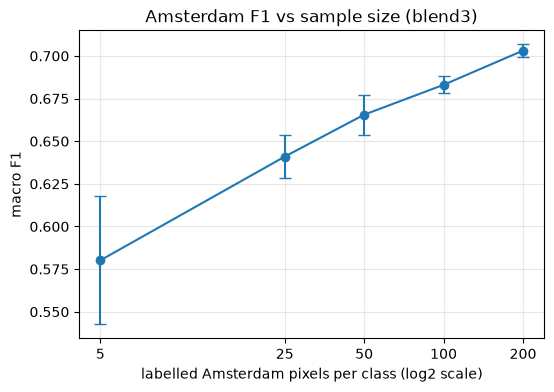

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(np.log2(table.n_per_class), table.f1_mean, yerr=table.f1_std, marker="o", capsize=4)
ax.set_xticks(np.log2(table.n_per_class)); ax.set_xticklabels(table.n_per_class)
ax.set_xlabel("labelled Amsterdam pixels per class (log2 scale)"); ax.set_ylabel("macro F1")
ax.set_title(f"Amsterdam F1 vs sample size ({METHOD})"); ax.grid(alpha=.3)
fig.savefig("f1_vs_log2n.png", dpi=150, bbox_inches="tight"); plt.show()

In [11]:
# Save one Amsterdam model per n (final method, seed 42) in the format predict.py expects,
# and check each saved file reproduces its score after reloading.
for n in SHOTS:
    f1, model = tv3.adapt_to_amsterdam(data, stage1, n, SEED, METHOD)
    path = f"models/amsterdam_{METHOD}_n{n:03d}_seed{SEED}.joblib"
    joblib.dump(model, path)
    qry = np.setdiff1d(np.arange(len(data["ya"])), model["support_index"])
    again = f1_score(data["ya"][qry], tv3.predict_blend3(joblib.load(path), stage1, data["Xa"][qry]), average="macro")
    assert abs(f1 - again) < 1e-9, "saved model does not reproduce its score"
    print(f"saved {path}  (F1 {f1:.4f}, reloaded {again:.4f})")

saved models/amsterdam_blend3_n005_seed42.joblib  (F1 0.5204, reloaded 0.5204)
saved models/amsterdam_blend3_n025_seed42.joblib  (F1 0.6286, reloaded 0.6286)
saved models/amsterdam_blend3_n050_seed42.joblib  (F1 0.6615, reloaded 0.6615)
saved models/amsterdam_blend3_n100_seed42.joblib  (F1 0.6826, reloaded 0.6826)
saved models/amsterdam_blend3_n200_seed42.joblib  (F1 0.6988, reloaded 0.6988)


In [12]:
# CHECK against Jian's run (within 2 standard deviations; average within 0.02)
targets = {5: 0.580, 25: 0.641, 200: 0.703}
for n, t in targets.items():
    if n in SHOTS:
        r = table[table.n_per_class == n].iloc[0]
        ok = abs(r.f1_mean - t) <= 2 * r.f1_std
        print(f"n={n:<4} got {r.f1_mean:.3f} +/- {r.f1_std:.3f}, expected {t:.3f} -> {'OK' if ok else 'CHECK'}")
print(f"average got {avg:.3f}, expected 0.655 -> {'OK' if abs(avg - 0.655) <= 0.02 else 'CHECK'}")
if madrid_cv: print(f"Madrid got {madrid_cv[0]:.3f}, expected 0.656 -> {'OK' if abs(madrid_cv[0] - 0.656) <= 2 * madrid_cv[1] + 0.01 else 'CHECK'}")

n=5    got 0.580 +/- 0.038, expected 0.580 -> OK
n=25   got 0.641 +/- 0.012, expected 0.641 -> OK
n=200  got 0.703 +/- 0.004, expected 0.703 -> OK
average got 0.655, expected 0.655 -> OK
Madrid got 0.656, expected 0.656 -> OK


## Step 6 - Spatial smoothing (blend3 vs blend3 + smoothing)

In [13]:
# Step 6: blend3 + spatial smoothing (same seeds as Step 4, so the comparison is fair).
# Each pixel's probabilities are mixed 50/50 with its 3x3 neighbours' average. Only predictions are used,
# never labels; support pixels are not used as neighbours. Expected average: about 0.671.
from sklearn.linear_model import LogisticRegression
ids_a = pd.read_parquet(FEATS("Amsterdam"), columns=["px_key", "py_key"]).to_numpy()   # same row order as data
rows = []
for n in SHOTS:
    plain, smooth = [], []
    for t in range(N_TRIALS):
        sup, qry = tv3.sample_support(data["ya"], n, SEED + t)
        ys = data["ya"][sup]
        Pf, _ = tv3.finetune_proba(data, sup, qry)                                          # (a) fine-tuned forest
        lr = LogisticRegression(C=tv3._c_for(n), max_iter=5000).fit(stage1["Zst"][sup], ys)  # (b) stack
        P = (Pf + lr.predict_proba(stage1["Zst"][qry]) + tv3.proto_proba(stage1["Za"], ys, sup, qry)) / 3
        S = tv3.smooth_proba(P, ids_a[qry], 0.5)
        plain.append(f1_score(data["ya"][qry], tv3.CLASSES[P.argmax(1)], average="macro"))
        smooth.append(f1_score(data["ya"][qry], tv3.CLASSES[S.argmax(1)], average="macro"))
    rows.append({"n_per_class": n, "blend3": np.mean(plain), "blend3_std": np.std(plain),
                 "blend3_smoothed": np.mean(smooth), "smoothed_std": np.std(smooth),
                 "wins_out_of_10": int((np.array(smooth) > np.array(plain)).sum())})
smooth_table = pd.DataFrame(rows).round(4)
smooth_table.to_csv(RES / "amsterdam_smoothing.csv", index=False)
print(smooth_table.to_string(index=False))
print("average blend3:", round(smooth_table.blend3.mean(), 4), "| average smoothed:", round(smooth_table.blend3_smoothed.mean(), 4))

 n_per_class  blend3  blend3_std  blend3_smoothed  smoothed_std  wins_out_of_10
           5  0.5801      0.0376           0.5934        0.0405              10
          25  0.6410      0.0125           0.6584        0.0118              10
          50  0.6656      0.0117           0.6835        0.0118              10
         100  0.6831      0.0051           0.7022        0.0060              10
         200  0.7031      0.0036           0.7194        0.0047              10
average blend3: 0.6546 | average smoothed: 0.6714
